<a href="https://colab.research.google.com/github/NithinReddychallagonda/RL_CAPSTONE_PROJECT/blob/main/RL_Capstone_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RL crop recommendation — four-model corrected executable research experiment

**Run from the first cell with Runtime → Run all.** This notebook runs a corrected one-step RL crop-classification experiment. The historical soil-transition environment is not part of the main training workflow. DQN, PPO, A2C, and **QR-DQN (Quantile Regression DQN)** are trained independently.

The dataset is downloaded using the original `atharvaingle/crop-recommendation-dataset` link. Train-only min/max ranges are used for normalization; crop-specific bounds are exported for analysis, not injected as test-label hints. Best checkpoints are selected using validation data and evaluated on the untouched test split only after training. **95% is a target, not a guaranteed or fabricated result.**

The one-step crop-label experiment is a contextual-bandit formulation, distinct from multi-step soil optimization. All 10 figures use training rollout data and/or validation checkpoints, not held-out test values. Detailed reward diagnostic charts focus on DQN; the cross-model charts include all four algorithms. Training four algorithms may take substantial time.

#An efficient framework for crop recommendation under dynamic field conditions using deep reinforcement learning

In [ ]:
# Install required libraries
%pip install -q "stable-baselines3[extra]>=2.3,<3" "sb3-contrib>=2.3,<3" "gymnasium>=0.29" kagglehub scikit-learn seaborn

In [ ]:
# Import libraries
import os,time,random,warnings,json
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
import kagglehub,gymnasium as gym
from gymnasium import spaces
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder,MinMaxScaler
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,f1_score
from stable_baselines3 import DQN,PPO,A2C
from sb3_contrib import QRDQN
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.vec_env import DummyVecEnv

# Set random seed and output folder
SEED=42
random.seed(SEED);np.random.seed(SEED)
OUT=Path('rl_research_results');OUT.mkdir(exist_ok=True)

# Download and load the crop recommendation dataset
DATASET='atharvaingle/crop-recommendation-dataset'
path=Path(kagglehub.dataset_download(DATASET))
files=list(path.rglob('Crop_recommendation.csv'))
if not files:raise FileNotFoundError('Crop_recommendation.csv missing from Kaggle download')
df_crop_rec=pd.read_csv(files[0]).rename(columns={'N':'Nitrogen_soil','P':'Phosphorus_soil','K':'Potassium_soil','temperature':'Temperature_C','humidity':'Humidity_%','ph':'pH_soil','rainfall':'Rainfall_mm','label':'Crop_Recommended'})

# Select features, clean the data and encode crop labels
FEATURES=['Nitrogen_soil','Phosphorus_soil','Potassium_soil','Temperature_C','Humidity_%','pH_soil','Rainfall_mm']
df_crop_rec=df_crop_rec.dropna(subset=FEATURES+['Crop_Recommended']).drop_duplicates().reset_index(drop=True)
le=LabelEncoder();
y=le.fit_transform(df_crop_rec['Crop_Recommended']);
X=df_crop_rec[FEATURES].astype('float32')

# Stratified 60/20/20 train/validation/test split (test set is used only for final evaluation)
X_tv,X_test,y_tv,y_test=train_test_split(X,y,test_size=.2,stratify=y,random_state=SEED)
X_train,X_val,y_train,y_val=train_test_split(X_tv,y_tv,test_size=.25,stratify=y_tv,random_state=SEED)

# Compute feature ranges from training data only (crop-wise ranges are saved for analysis, not used by the models)
train_ranges=X_train.agg(['min','max']).T;
train_ranges.columns=['train_min','train_max']
assert (train_ranges.train_max>=train_ranges.train_min).all()
crop_ranges=X_train.assign(Crop_Recommended=le.inverse_transform(y_train)).groupby('Crop_Recommended')[FEATURES].agg(['min','max'])
train_ranges.to_csv(OUT/'train_feature_ranges.csv');crop_ranges.to_csv(OUT/'train_crop_ranges.csv')
print('Train/validation/test:',len(X_train),len(X_val),len(X_test));
display(train_ranges);
display(crop_ranges)
print('These training-derived bounds normalize observations; they do not guarantee accuracy or prove soil transitions.')

# Normalize features to [0,1] using a scaler fitted on training data
scaler=MinMaxScaler(feature_range=(0,1),clip=True).fit(X_train)
xt=scaler.transform(X_train).astype('float32');
xv=scaler.transform(X_val).astype('float32');
xs=scaler.transform(X_test).astype('float32')

Using Colab cache for faster access to the 'crop-recommendation-dataset' dataset.
Train/validation/test: 1320 440 440


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,train_min,train_max
Nitrogen_soil,0.000000,140.000000
Phosphorus_soil,5.000000,145.000000
Potassium_soil,5.000000,205.000000
Temperature_C,8.825675,43.360516
Humidity_%,14.273280,99.981873
pH_soil,3.510404,9.935091
Rainfall_mm,20.490356,298.401855


Nitrogen_soil        Phosphorus_soil        Potassium_soil  \
                           min    max             min    max            min   
Crop_Recommended                                                              
apple                      0.0   40.0           120.0  145.0          195.0   
banana                    80.0  120.0            70.0   95.0           45.0   
blackgram                 20.0   59.0            55.0   80.0           15.0   
chickpea                  20.0   60.0            55.0   80.0           75.0   
coconut                    0.0   40.0             5.0   30.0           25.0   
coffee                    80.0  120.0            15.0   40.0           25.0   
cotton                   100.0  140.0            35.0   60.0           15.0   
grapes                     0.0   40.0           120.0  145.0          195.0   
jute                      60.0  100.0            35.0   60.0           35.0   
kidneybeans                0.0   40.0            55.0   80.0           15.0   
lentil                     0.0   40.0            55.0   80.0           15.0   
maize                     60.0  100.0            35.0   60.0           15.0   
mango                      0.0   40.0            15.0   40.0           25.0   
mothbeans                  0.0   40.0            35.0   60.0           15.0   
mungbean                   1.0   40.0            35.0   60.0           15.0   
muskmelon                 80.0  120.0             5.0   30.0           45.0   
orange                     0.0   39.0             5.0   30.0            5.0   
papaya                    31.0   70.0            46.0   69.0           45.0   
pigeonpeas                 0.0   39.0            55.0   80.0           15.0   
pomegranate                0.0   40.0             6.0   30.0           35.0   
rice                      60.0   99.0            35.0   60.0           35.0   
watermelon                80.0  120.0             5.0   30.0           45.0   

                        Temperature_C            Humidity_%             \
                    max           min        max        min        max   
Crop_Recommended                                                         
apple             205.0     21.131607  23.996862  90.098778  94.896133   
banana             55.0     25.058022  29.908886  75.031929  84.978493   
blackgram          25.0     25.198578  34.946617  60.065350  69.843544   
chickpea           85.0     17.091042  20.931753  14.273280  19.969790   
coconut            35.0     25.028872  29.709312  90.017342  99.981873   
coffee             35.0     23.106939  27.773634  50.045570  69.948074   
cotton             25.0     22.000851  25.992374  75.005394  84.862755   
grapes            205.0      8.825675  41.656029  80.016396  83.983521   
jute               45.0     23.128443  26.985823  70.882599  89.891068   
kidneybeans        25.0     15.330426  24.903582  18.092241  24.969698   
lentil             25.0     18.064861  29.944139  60.268543  69.558632   
maize              25.0     18.254053  26.549864  55.282204  73.625481   
mango              35.0     27.107109  35.960545  45.416920  54.964054   
mothbeans          25.0     24.018253  31.969879  40.009335  64.955856   
mungbean           25.0     27.014704  29.892328  80.034996  89.929085   
muskmelon          55.0     27.048635  29.916906  90.015060  94.876793   
orange             15.0     10.356096  34.740051  90.006218  94.964195   
papaya             55.0     23.168558  43.360516  90.038628  94.944824   
pigeonpeas         25.0     18.319105  36.750874  30.986855  69.691414   
pomegranate        45.0     18.071329  24.962732  85.401711  94.950317   
rice               45.0     20.280193  26.929951  80.158363  84.943756   
watermelon         55.0     24.214956  26.897501  80.026215  89.735245   

                   pH_soil           Rainfall_mm              
                       min       max         min         max  
Crop_Recommended                                              
a

These training-derived bounds normalize observations; they do not guarantee accuracy or prove soil transitions.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Environment and reward definition
Each episode contains **one** crop choice for a sampled training record. Correct label = +1; incorrect label = 0. This nonnegative reward measures correct decisions; positive mean reward does NOT establish improved accuracy. Original 20-step soil-simulation penalties remain unchanged. The observation is the seven training-min/max-normalized features, clipped to [0,1]. There is no label or Random Forest prediction in the observation. This is a contextual-bandit formulation, not multi-season soil optimization. As every episode is one step, average episode length is expected to be 1 and reward std is tied to accuracy. Training data and validation data are disjoint.

In [ ]:
# One-step environment: reward is 1 for the correct crop, otherwise 0
class CropLabelEnv(gym.Env):
    metadata={'render_modes':[]}
    def __init__(self,features,labels,seed=42):
        super().__init__();
        self.features=np.asarray(features,dtype=np.float32);
        self.labels=np.asarray(labels,dtype=np.int64)
        self.observation_space=spaces.Box(0,1,shape=(self.features.shape[1],),dtype=np.float32)
        self.action_space=spaces.Discrete(len(le.classes_));
        self.i=0;self._seed=seed

    def reset(self, *, seed=None, options=None):
      super().reset(seed=seed)
      self.i = int(self.np_random.integers(len(self.labels)))
      return self.features[self.i].copy(), {}
    def step(self,action):
        correct=int(int(action)==int(self.labels[self.i]));reward=1.0 if correct else 0.0
        return self.features[self.i].copy(),reward,True,False,{'correct':correct,'target':int(self.labels[self.i])}

# Evaluate a model on every record using deterministic predictions
def evaluate_labels(agent,features,labels,batch=256):
    pred=[]
    for start in range(0,len(features),batch):
        p,_=agent.predict(features[start:start+batch],deterministic=True)
        pred.extend(np.asarray(p).reshape(-1).astype(int).tolist())
    pred=np.asarray(pred);correct=(pred==labels);reward=correct.astype(float)
    return {'accuracy':float(correct.mean()),'success_rate':float(correct.mean()*100),
            'avg_cumulative_reward':float(reward.mean()),'reward_std':float(reward.std(ddof=1)) if len(reward)>1 else 0.,
            'avg_episode_length':1.,'macro_f1':float(f1_score(labels,pred,average='macro',zero_division=0))},pred

## Training and checkpoint evaluation
The 95% accuracy target is a **validation goal**, not a guarantee. The best validation checkpoint is saved for each algorithm, and the untouched test split is evaluated only after training. All algorithms use the same environment, data split, and validation checkpoint interval; training budgets are recorded explicitly in `TOTAL_STEPS` (DQN and QR-DQN use 150,000 steps; PPO and A2C use 75,000 each). No test metrics are used for model or checkpoint selection. The original soil-simulation environment's reward scale is not used in this contextual-bandit experiment.

**Fourth model — QR-DQN:** QR-DQN is a distributional extension of DQN that learns quantiles of the return distribution. The quantile count is configured through the policy arguments. It is included as a fourth comparison model; better accuracy is not guaranteed.

In [ ]:
# Training settings
TOTAL_STEPS={"DQN":150000,"PPO":150000,"A2C":150000,"QR-DQN":150000}
EVAL_EVERY=5000
TARGET_ACCURACY=.95

# Callback: evaluate on validation data, log training rewards and save the best model
# (PPO/A2C collect rollout batches, so their checkpoint steps are approximate)
class ResearchCallback(BaseCallback):
    def __init__(self,name):
        super().__init__()
        self.name=name
        self.history=[]
        self.rollout_rewards=[]
        self.next_eval=EVAL_EVERY
        self.best_val=-1.0
        self.best_path=OUT/f"{name}_best_validation"

    def _on_step(self):
        self.rollout_rewards.extend(np.asarray(self.locals['rewards'],dtype=float).ravel().tolist())
        if self.num_timesteps>=self.next_eval:
            val,_=evaluate_labels(self.model,xv,y_val)
            recent=np.asarray(self.rollout_rewards[-EVAL_EVERY:])
            self.history.append({'algorithm':self.name,'timesteps':self.num_timesteps,**val,
                'train_reward_mean':float(recent.mean()),'train_reward_std':float(recent.std()),
                'train_success_rate':float(100*np.mean(recent>0)),
                'train_reward_min':float(recent.min()),'train_reward_max':float(recent.max())})
            if val['accuracy']>self.best_val:
                self.best_val=val['accuracy']
                self.model.save(str(self.best_path))
            print(self.name,self.num_timesteps,'training reward',round(recent.mean(),3),
                  'validation accuracy',round(val['accuracy'],4),'best validation',round(self.best_val,4))
            self.next_eval+=EVAL_EVERY
        return True

# Hyperparameters for DQN, PPO, A2C and QR-DQN
CONFIGS={
    'DQN':(DQN,{
        'learning_rate':3e-4,'buffer_size':50000,'learning_starts':2000,
        'batch_size':256,'train_freq':4,'gradient_steps':2,
        'exploration_fraction':.20,'exploration_final_eps':.02,
        'target_update_interval':1000,'policy_kwargs':{'net_arch':[256,256]}
    }),
    'PPO':(PPO,{
        'learning_rate':3e-4,'n_steps':1024,'batch_size':256,'n_epochs':5,
        'policy_kwargs':{'net_arch':[128,128]}
    }),
    'A2C':(A2C,{
        'learning_rate':7e-4,'n_steps':32,
        'policy_kwargs':{'net_arch':[128,128]}
    }),
    'QR-DQN':(QRDQN,{
        'learning_rate':3e-4,'buffer_size':50000,'learning_starts':2000,
        'batch_size':256,'train_freq':4,'gradient_steps':2,
        'exploration_fraction':.20,'exploration_final_eps':.02,
        'target_update_interval':1000,'policy_kwargs':{'net_arch':[256,256],'n_quantiles':50}
    })
}

# Train each model and restore its best validation checkpoint
models={}
histories={}
callbacks={}
training_seconds={}

for name,(cls,kwargs) in CONFIGS.items():
    vec=DummyVecEnv([lambda:CropLabelEnv(xt,y_train,seed=SEED)])
    agent=cls('MlpPolicy',vec,verbose=0,seed=SEED,device='auto',**kwargs)
    cb=ResearchCallback(name)
    t0=time.perf_counter()
    agent.learn(total_timesteps=TOTAL_STEPS[name],callback=cb,progress_bar=False)
    training_seconds[name]=time.perf_counter()-t0

    if cb.best_path.with_suffix('.zip').exists():
        agent=cls.load(str(cb.best_path),env=vec,device='auto')
    models[name]=agent
    callbacks[name]=cb
    histories[name]=pd.DataFrame(cb.history)
    histories[name].to_csv(OUT/f'{name}_training_checkpoints.csv',index=False)
    agent.save(str(OUT/f'{name.replace("-", "_")}_selected_model'))
    print(name,'best validation accuracy:',round(cb.best_val*100,2),'%')
    print(name,'training seconds:',round(training_seconds[name],1))
    vec.close()

DQN 5000 training reward 0.089 validation accuracy 0.9159 best validation 0.9159


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


DQN 10000 training reward 0.276 validation accuracy 0.9659 best validation 0.9659


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


DQN 15000 training reward 0.439 validation accuracy 0.9795 best validation 0.9795


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (230 outputs left out)

QR-DQN 145000 training reward 0.983 validation accuracy 0.9841 best validation 0.9864


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


QR-DQN 150000 training reward 0.978 validation accuracy 0.9864 best validation 0.9864
QR-DQN best validation accuracy: 98.64 %
QR-DQN training seconds: 300.7


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Evaluation metrics and held-out accuracy
Convergence speed is the earliest checkpoint from which validation accuracy remains ≥95% through the end of training; sample efficiency is the first checkpoint reaching ≥95% validation accuracy. If never reached, both are reported **not reached**, rather than inventing a value. Inference timing is per record on the same machine, with warmup. Test data are evaluated only here, after all training is complete. The one-step success rate equals crop-label accuracy by definition. Results are reported for DQN, PPO, A2C, and QR-DQN.

In [ ]:
# Target accuracy for the final evaluation
TARGET_ACCURACY = 0.85

# Find sample efficiency and convergence speed
def threshold_metrics(h, target=TARGET_ACCURACY):
    ok = h.accuracy.to_numpy() >= target
    steps = h.timesteps.to_numpy()
    first = int(steps[np.flatnonzero(ok)[0]]) if ok.any() else np.nan
    stable = next((int(steps[i]) for i in range(len(ok)) if ok[i:].all()), np.nan)
    return first, stable

# Measure inference time per decision
def timed_inference(agent, features, repeats=3):
    for x in features[:20]:
        agent.predict(x, deterministic=True)
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        for x in features:
            agent.predict(x, deterministic=True)
        times.append((time.perf_counter() - t0) * 1000 / len(features))
    return float(np.median(times))

# Evaluate all four models on the held-out test set
rows = []
test_predictions = {}

for name, agent in models.items():
    first, stable = threshold_metrics(histories[name])
    metrics, pred = evaluate_labels(agent, xs, y_test)
    test_predictions[name] = pred
    rows.append({
        'Algorithm': name,
        'Held-out RL accuracy (%)': 100 * metrics['accuracy'],
        'Average cumulative reward': metrics['avg_cumulative_reward'],
        'Success rate (%)': metrics['success_rate'],
        'Average episode length': metrics['avg_episode_length'],
        'Reward standard deviation': metrics['reward_std'],
        'Convergence speed (steps)': stable,
        'Sample efficiency (steps)': first,
        'Inference time (ms/decision)': timed_inference(agent, xs),
        'Macro F1': metrics['macro_f1'],
        'Training time (s)': training_seconds[name]
    })

# Create, display and save the results table
summary = pd.DataFrame(rows)
summary_rounded = summary.round(4)

display_table = summary_rounded.astype(object).where(
    summary_rounded.notna(), "Not reached"
)

print("FINAL RESULTS: FOUR RL MODELS")
print(f"TARGET ACCURACY: {TARGET_ACCURACY*100:.0f}%")
display(display_table)

summary.to_csv(
    OUT / 'final_8_metrics_and_accuracy.csv',
    index=False,
    na_rep='Not reached'
)

# Check each model against the target accuracy
for _, row in summary.iterrows():
    accuracy = row['Held-out RL accuracy (%)']
    print(
        f"{row['Algorithm']} held-out test accuracy "
        f">={TARGET_ACCURACY*100:.0f}%: "
        f"{bool(accuracy >= TARGET_ACCURACY*100)}"
    )

print("Held-out test results are reported for analysis only; they are not used for model selection.")
print("A positive reward is not evidence of target accuracy; report test accuracy and macro-F1 separately.")
print("Training-derived ranges:", OUT / 'train_feature_ranges.csv')

FINAL RESULTS: FOUR RL MODELS
TARGET ACCURACY: 85%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Algorithm,Held-out RL accuracy (%),Average cumulative reward,Success rate (%),Average episode length,Reward standard deviation,Convergence speed (steps),Sample efficiency (steps),Inference time (ms/decision),Macro F1,Training time (s)
0,DQN,99.3182,0.9932,99.3182,1.0,0.0824,5000,5000,1.0137,0.9932,280.0226
1,PPO,92.5,0.925,92.5,1.0,0.2637,60000,60000,1.5212,0.9078,221.4049
2,A2C,87.2727,0.8727,87.2727,1.0,0.3337,105000,105000,0.7278,0.842,231.4061
3,QR-DQN,98.8636,0.9886,98.8636,1.0,0.1061,5000,5000,0.4142,0.9886,300.7141


DQN held-out test accuracy >=85%: True
PPO held-out test accuracy >=85%: True
A2C held-out test accuracy >=85%: True
QR-DQN held-out test accuracy >=85%: True
Held-out test results are reported for analysis only; they are not used for model selection.
A positive reward is not evidence of target accuracy; report test accuracy and macro-F1 separately.
Training-derived ranges: rl_research_results/train_feature_ranges.csv


## Ten different graph types — training and validation values only
All graphs below use training rollout rewards and/or validation checkpoints collected **during training**. No held-out test values appear in any graph. Validation curves are clearly labeled as validation, not training. Graphs 7–9 use DQN training rewards grouped into consecutive equal-length training windows. The cross-model success-rate chart and validation heatmap include all four algorithms.

In [ ]:
# Import plotting libraries
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Install Times New Roman font
!apt-get update -qq
!echo "ttf-mscorefonts-installer msttcorefonts/accepted-mscorefonts-eula select true" | debconf-set-selections
!DEBIAN_FRONTEND=noninteractive apt-get install -y ttf-mscorefonts-installer
!fc-cache -f

# Register the font and verify it is available
font_dir = "/usr/share/fonts/truetype/msttcorefonts"
font_files = fm.findSystemFonts(fontpaths=[font_dir])

for font_file in font_files:
    fm.fontManager.addfont(font_file)

available_fonts = {font.name for font in fm.fontManager.ttflist}

if "Times New Roman" not in available_fonts:
    raise RuntimeError(
        "Times New Roman was not installed successfully. "
        "Check the installation output above."
    )

# Set global plot font style and size
plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 12,
    "axes.titlesize": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 12
})

print("Font: Times New Roman")
print("Font size: 12 pt")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  cabextract distro-info libmspack0t64 python3-chardet python3-debconf
  python3-debian python3-distro-info python3-distupgrade
  python3-update-manager python3-yaml ubuntu-pro-client ubuntu-pro-client-l10n
  ubuntu-release-upgrader-core update-manager-core update-notifier-common
  xfonts-encodings xfonts-utils zstd
Suggested packages:
  shunit2 policykit-1
The following NEW packages will be installed:
  cabextract distro-info libmspack0t64 python3-chardet python3-debconf
  python3-debian python3-distro-info python3-distupgrade
  python3-update-manager python3-yaml ttf-mscorefonts-installer
  ubuntu-pro-client ubuntu-pro-client-l10n ubuntu-release-upgra

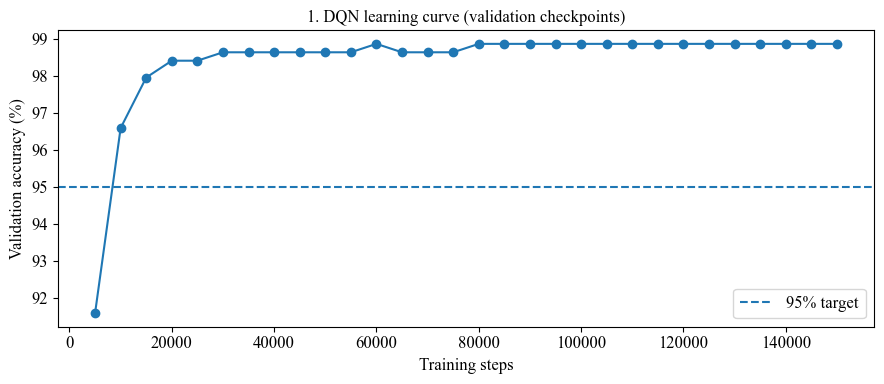

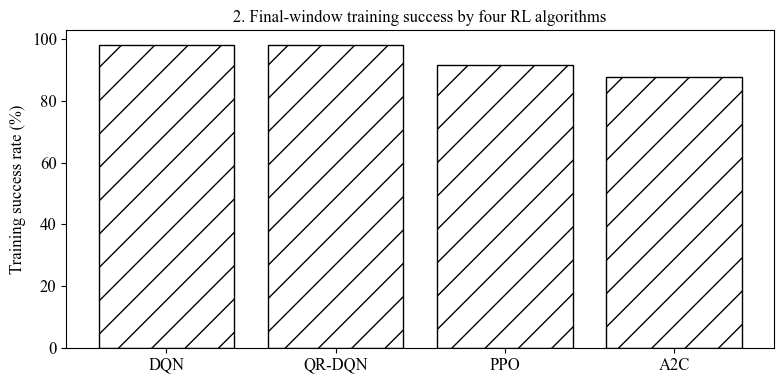

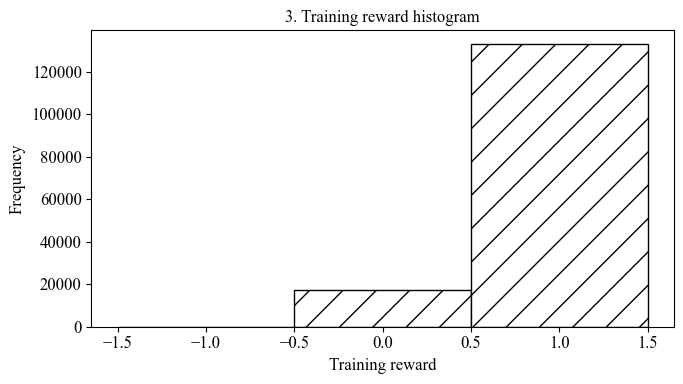

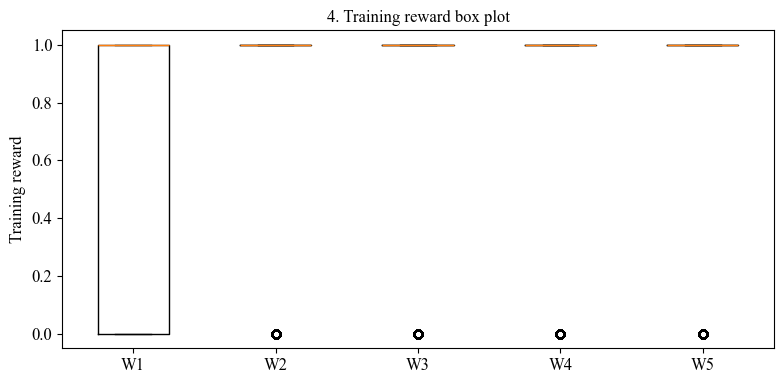

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


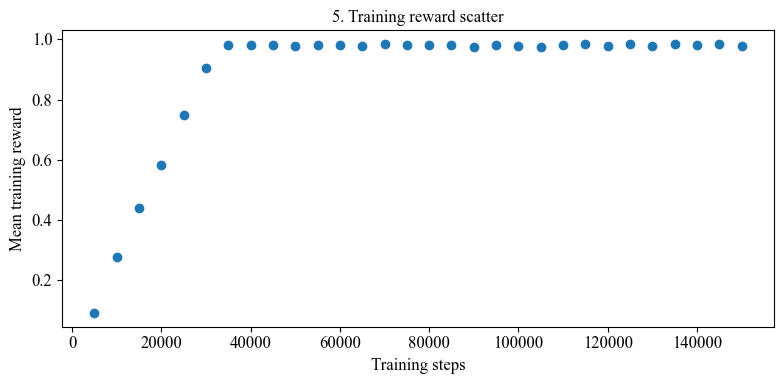

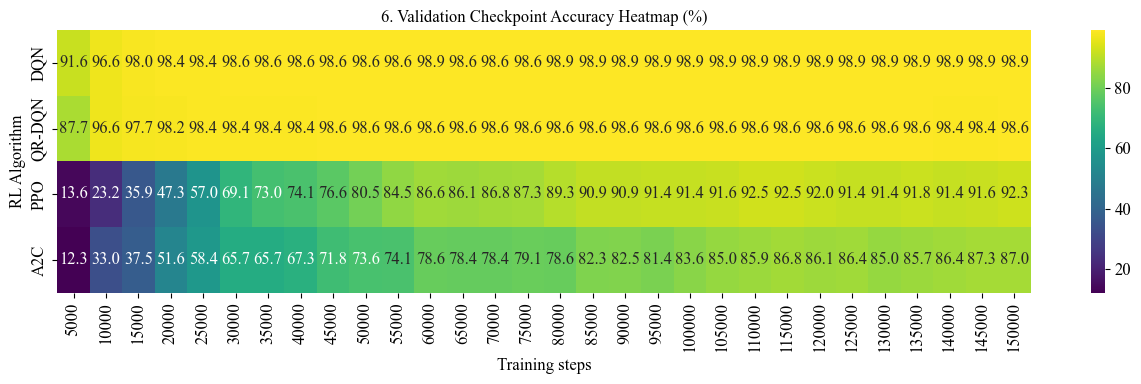

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


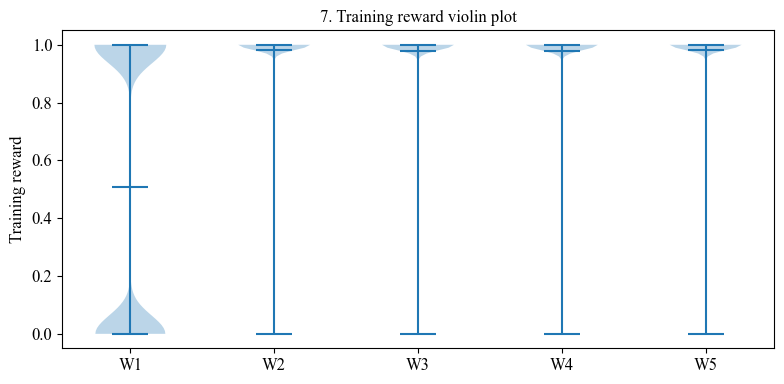

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


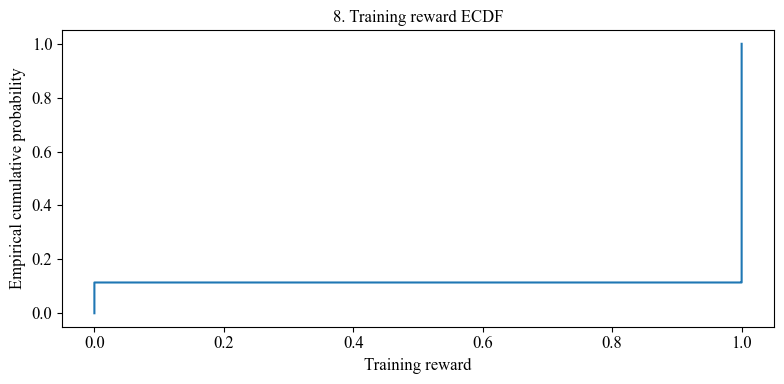

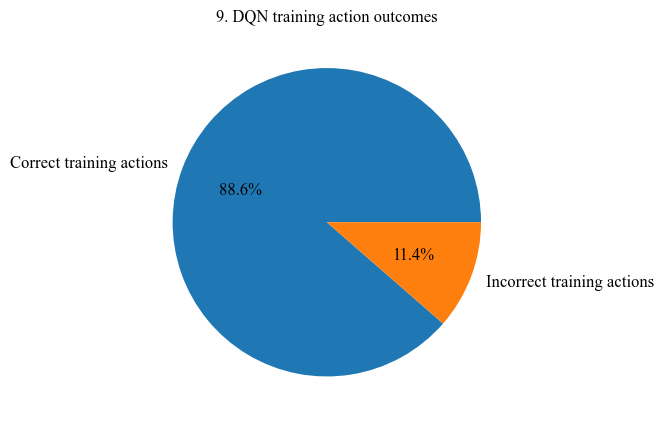

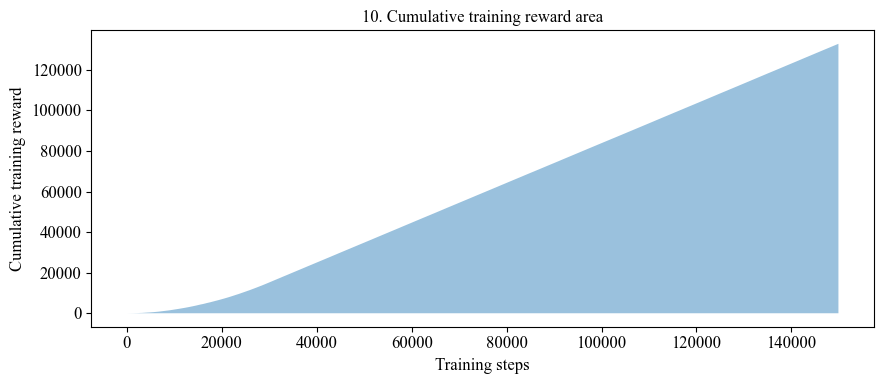

Saved 10 training/validation-only figures to /content/rl_research_results
Models included: DQN, PPO, A2C, QR-DQN


In [ ]:
# Prepare DQN training history and reward windows
from collections import Counter
h=histories['DQN'];
r=np.asarray(callbacks['DQN'].rollout_rewards,dtype=float);
t=np.arange(1,len(r)+1)
window_edges=np.linspace(0,len(r),6,dtype=int)
windows=[r[window_edges[i]:window_edges[i+1]] for i in range(5)]

# Helper function to save and show figures
def savefig(k,name):
    plt.tight_layout();
    plt.savefig(OUT/f'{k:02d}_{name}.png',dpi=220,bbox_inches='tight');
    plt.show()

# 1. DQN validation accuracy during training
plt.figure(figsize=(9,4));
plt.plot(h.timesteps,100*h.accuracy,marker='o');
plt.axhline(95,ls='--',label='95% target');
plt.legend();plt.xlabel('Training steps');
plt.ylabel('Validation accuracy (%)');
plt.title('1. DQN learning curve (validation checkpoints)');
savefig(1,'line_validation_accuracy')

# 2. Algorithm training success rate with diagonal hatching
model_order=['DQN','QR-DQN','PPO','A2C']
model_order=[k for k in model_order if k in histories]
plt.figure(figsize=(8,4));
plt.bar(model_order,[histories[k].train_success_rate.iloc[-1] for k in model_order],facecolor='white',edgecolor='black',hatch='/',linewidth=1);
plt.ylabel('Training success rate (%)');
plt.title('2. Final-window training success by four RL algorithms');
savefig(2,'bar_training_success')

# 3. DQN training rollout reward histogram with diagonal hatching
plt.figure(figsize=(7,4));
plt.hist(r,bins=[-1.5,-.5,.5,1.5],facecolor='white',edgecolor='black',hatch='/',linewidth=1);
plt.xlabel('Training reward');
plt.ylabel('Frequency');
plt.title('3. Training reward histogram');
savefig(3,'hist_training_reward')

# 4. DQN training reward across windows
plt.figure(figsize=(8,4));
plt.boxplot(windows,tick_labels=[f'W{i}' for i in range(1,6)]);
plt.ylabel('Training reward');
plt.title('4. Training reward box plot');
savefig(4,'box_training_reward')

# 5. Training steps vs DQN mean rollout reward
plt.figure(figsize=(8,4));
plt.scatter(h.timesteps,h.train_reward_mean);
plt.xlabel('Training steps');
plt.ylabel('Mean training reward');
plt.title('5. Training reward scatter');
savefig(5,'scatter_training_reward')

# 6. Validation accuracy heatmap for all RL algorithms
pivot=pd.concat(histories.values(),ignore_index=True).pivot(index='algorithm',columns='timesteps',values='accuracy')*100
model_order=['DQN','QR-DQN','PPO','A2C']
model_order=[m for m in model_order if m in pivot.index]
pivot=pivot.reindex(model_order)
plt.figure(figsize=(13,4));
sns.heatmap(pivot,annot=True,fmt='.1f',cmap='viridis');
plt.xlabel('Training steps');
plt.ylabel('RL Algorithm');
plt.title('6. Validation Checkpoint Accuracy Heatmap (%)');
savefig(6,'heatmap_validation')

# 7. DQN training reward per window
plt.figure(figsize=(8,4));
plt.violinplot(windows,showmeans=True);
plt.xticks(range(1,6),[f'W{i}' for i in range(1,6)]);
plt.ylabel('Training reward');
plt.title('7. Training reward violin plot');savefig(7,'violin_training_reward')

# 8. DQN training reward ECDF
s=np.sort(r);
plt.figure(figsize=(8,4));
plt.step(s,np.arange(1,len(s)+1)/len(s),where='post');
plt.xlabel('Training reward');
plt.ylabel('Empirical cumulative probability');
plt.title('8. Training reward ECDF');
savefig(8,'ecdf_training_reward')

# 9. Positive vs negative DQN training rewards
plt.figure(figsize=(6,5));
plt.pie([np.sum(r>0),np.sum(r<=0)],labels=['Correct training actions','Incorrect training actions'],autopct='%1.1f%%');
plt.title('9. DQN training action outcomes');
savefig(9,'pie_training_outcomes')

# 10. Cumulative DQN training rewards
stride=max(1,len(r)//2000);
plt.figure(figsize=(9,4));
plt.fill_between(t[::stride],np.cumsum(r)[::stride],alpha=.45);
plt.xlabel('Training steps');
plt.ylabel('Cumulative training reward');
plt.title('10. Cumulative training reward area');
savefig(10,'area_cumulative_training_reward')

print('Saved 10 training/validation-only figures to',OUT.resolve())
print('Models included:',', '.join(models.keys()))